<a href="https://colab.research.google.com/github/DaoNguyenMinhThy/Machine_Learning/blob/main/Lab05_CayQuyetDinh_RungNgauNhien.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# -*- coding: utf-8 -*-
"""Bước 1: tự tính chỉ số Gini và tự chọn câu hỏi tốt nhất.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

# Mười khách vay để tính tay, giống hệt bảng trên slide
nho = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)


g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}")
print()

# Thử mọi ngưỡng nằm giữa hai mức thu nhập liền nhau
thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print(" nguong Gini sau chia Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f" {nguong:6.1f} {g:13.4f} {g_goc - g:9.4f}")
print()

# Câu hỏi thứ hai: có việc làm ổn định không
viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f" Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}")
print()

# Để scikit-learn tự chọn câu hỏi đầu tiên rồi so với bảng ở trên
cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))

Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
 nguong Gini sau chia Gini giam
    7.0        0.4000    0.0800
    8.5        0.4750    0.0050
   10.0        0.4190    0.0610
   12.0        0.3167    0.1633
   14.0        0.4000    0.0800
   16.5        0.4500    0.0300
   19.0        0.3429    0.1371
   22.5        0.4000    0.0800
   27.5        0.4444    0.0356

Cau hoi 'co viec on dinh ?'
 Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



In [6]:
# -*- coding: utf-8 -*-
"""Bước 2: học một cây nhỏ năm lá trên dữ liệu khách vay rồi đọc nó."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv("khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Giới hạn cây chỉ được có 5 lá để còn đọc được bằng mắt
cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc     : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra: {a_kt:.4f}")
print()

# Hai khách mới, đi theo cây để biết mỗi người rơi vào lá nào
moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]
for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accu

In [7]:
# -*- coding: utf-8 -*-
"""Bước 3: để cây mọc tự do, rồi chọn độ sâu bằng kiểm định chéo."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Không đặt giới hạn nào, cây chia tới khi mọi lá đều thuần
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f" do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f" tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")
print()

# Chọn độ sâu chỉ dựa trên tập học
print("Do sau tap hoc kiem dinh cheo")
diem = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {d:2d} {hoc:.4f} {diem[d]:.4f}")
d_tot = max(diem, key=diem.get)
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra {acc:.4f}")

Cay moc tu do
 do sau 13, so la 92
 tap hoc 1.0000, tap kiem tra 0.7667

Do sau tap hoc kiem dinh cheo
  1 0.7467 0.7244
  2 0.7711 0.7378
  3 0.8000 0.7511
  4 0.8644 0.8089
  5 0.8978 0.8333
  6 0.9133 0.8156
  7 0.9400 0.8067
  8 0.9600 0.7733
  9 0.9800 0.7800
 10 0.9911 0.7822
 11 0.9933 0.7756
 12 0.9978 0.7778
 13 1.0000 0.7733
 14 1.0000 0.7733
 15 1.0000 0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra 0.8533


In [8]:
# -*- coding: utf-8 -*-
"""Bước 4: kiểm chứng cây không cần chuẩn hoá dữ liệu."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)


# Cây 1: dữ liệu gốc
goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

# Cây 2: dữ liệu đã chuẩn hoá, trung bình tính trên riêng tập học
sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

# Cây 3: đổi thu nhập từ triệu đồng sang nghìn đồng
X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f" du lieu goc         : {accuracy_score(y_te, du_goc):.4f}")
print(f" da chuan hoa        : {accuracy_score(y_te, du_chuan):.4f}")
print(f" thu nhap nghin dong : {accuracy_score(y_te, du_nghin):.4f}")
print()
print("So khach bi doan khac cay goc")
print(f" da chuan hoa        : {(du_chuan != du_goc).sum()}")
print(f" thu nhap nghin dong : {(du_nghin != du_goc).sum()}")
print()
print("Nguong cua cau hoi goc")
print(f" du lieu goc         : {goc.tree_.threshold[0]:.2f}")
print(f" thu nhap nghin dong : {nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
 du lieu goc         : 0.8533
 da chuan hoa        : 0.8533
 thu nhap nghin dong : 0.8533

So khach bi doan khac cay goc
 da chuan hoa        : 0
 thu nhap nghin dong : 0

Nguong cua cau hoi goc
 du lieu goc         : 15.05
 thu nhap nghin dong : 15050.00


In [9]:
# -*- coding: utf-8 -*-
"""Bước 5: trồng rừng ngẫu nhiên và so với một cây."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Bốc mẫu có hoàn lại: rút 450 lần từ 450 khách
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})")
print()

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f" tap hoc     : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f" tap kiem tra: {accuracy_score(y_te, rung.predict(X_te)):.4f}")
print()

print("So cay accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    print(f" {m:4d} {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

# Bảng tổng kết ba mô hình trên cùng tập kiểm tra
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}
print("Mo hinh        tap hoc tap kiem tra")
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f" {ten:14s} {a:.4f} {b:.4f}")

Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
 tap hoc     : 1.0000
 tap kiem tra: 0.9000

So cay accuracy tap kiem tra
    1 0.7933
   10 0.8467
   50 0.8733
  200 0.9000
  400 0.9000

Mo hinh        tap hoc tap kiem tra
 Cay moc tu do  1.0000 0.7667
 Cay sau 5      0.8978 0.8533
 Rung 200 cay   1.0000 0.9000


In [10]:
# -*- coding: utf-8 -*-
"""Bước 6: đọc độ quan trọng của đặc trưng, và thấy giới hạn của nó."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
qt = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3))
print()

# Thêm một cột toàn số ngẫu nhiên, chẳng liên quan gì tới việc trả nợ
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)
qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(qt_nn.sort_values(ascending=False).round(3).to_string())

Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


In [11]:
# -*- coding: utf-8 -*-
"""Bước 7: cây quyết định cho bài toán hồi quy, trên dữ liệu giá nhà."""

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print(f"Cay hoi quy sau 3 co {cay.get_n_leaves()} la")
print(export_text(cay, feature_names=["dien_tich"], decimals=1))

print("MAE tren tap kiem tra (ty dong)")
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f" Cay sau 3  : {mae_cay:.4f}")
print(f" Duong thang: {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print(" dien tich cay duong thang")
for dt, a, b in zip(can_moi["dien_tich"], cay.predict(can_moi),
                    duong.predict(can_moi)):
    print(f" {dt:6.0f} m2 {a:6.2f} {b:6.2f}")

Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
 Cay sau 3  : 0.5039
 Duong thang: 0.2578

Du doan cho bon can moi (ty dong)
 dien tich cay duong thang
     60 m2   4.92   5.12
    100 m2   8.32   8.24
    150 m2   9.40  12.13
    250 m2   9.40  19.91


# 9. Bài tập

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cay_nam_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay_nam_la.fit(X_tr, y_tr)

plt.figure(figsize=(14, 8))
plot_tree(
    cay_nam_la,
    feature_names=list(X.columns),
    class_names=["tre han", "dung han"],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.tight_layout()
plt.savefig("cay_nam_la.png", dpi=150)
plt.close()
print("Da luu cay_nam_la.png")
print()

cay_sau_2 = DecisionTreeClassifier(max_depth=2, random_state=0)
cay_sau_2.fit(X_tr, y_tr)

print("Cau truc cay sau 2:")
print(export_text(cay_sau_2, feature_names=list(X.columns), show_weights=True, decimals=3))

plt.figure(figsize=(12, 6))
plot_tree(
    cay_sau_2,
    feature_names=list(X.columns),
    class_names=["tre han", "dung han"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.tight_layout()
plt.savefig("cay_sau_2.png", dpi=150)
plt.close()
print("Da luu cay_sau_2.png")
print()

print("Cau hoi 1: Hai la ben trai cua cay sau 2 co cung ket luan khong?")
print("Tra loi  : Co, ca hai la ben trai deu ket luan la tre han (lop 0).")
print()
print("Cau hoi 2: Vi sao cay van chia nut do ra lam hai?")
print("Tra loi  : Vi thuat toan chon cau hoi nham giam chi so Gini trung binh co trong so (tang do thuan khiet cua hai nut con), khong bat buoc hai la phai khac nhan ngay. Nho vay cay tach rieng duoc nhom 128 khach rat thuan khiet (114 tre han, gini = 0.195) de tiep tuc chia o tang sau.")

Da luu cay_nam_la.png

Cau truc cay sau 2:
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- weights: [68.000, 53.000] class: 0
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Da luu cay_sau_2.png

Cau hoi 1: Hai la ben trai cua cay sau 2 co cung ket luan khong?
Tra loi  : Co, ca hai la ben trai deu ket luan la tre han (lop 0).

Cau hoi 2: Vi sao cay van chia nut do ra lam hai?
Tra loi  : Vi thuat toan chon cau hoi nham giam chi so Gini trung binh co trong so (tang do thuan khiet cua hai nut con), khong bat buoc hai la phai khac nhan ngay. Nho vay cay tach rieng duoc nhom 128 khach rat thuan khiet (114 tre han, gini = 0.195) de tiep tuc chia o tang sau.


cay_nam_la.png:
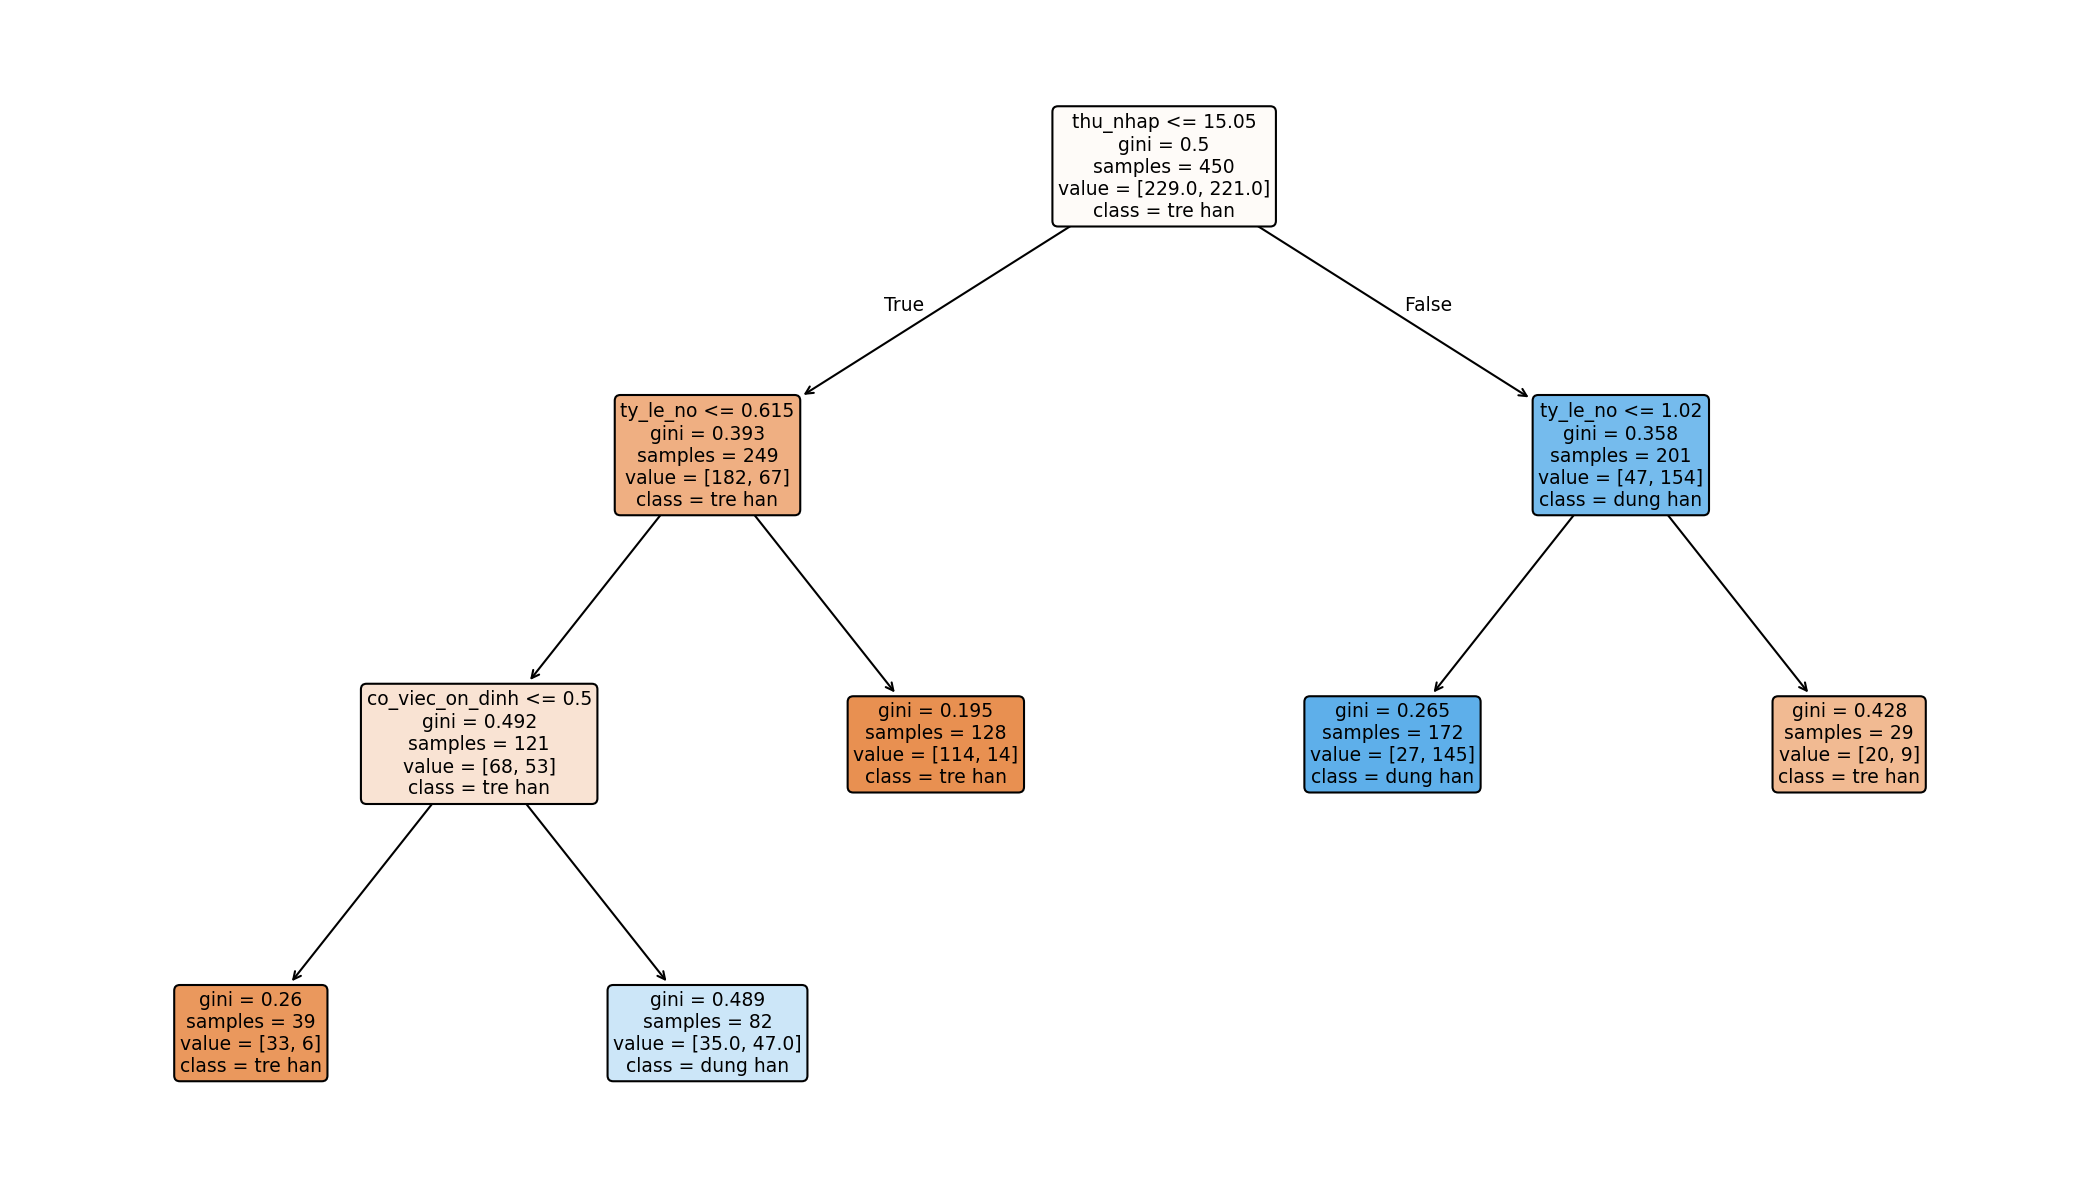

cay_sau_2.png:
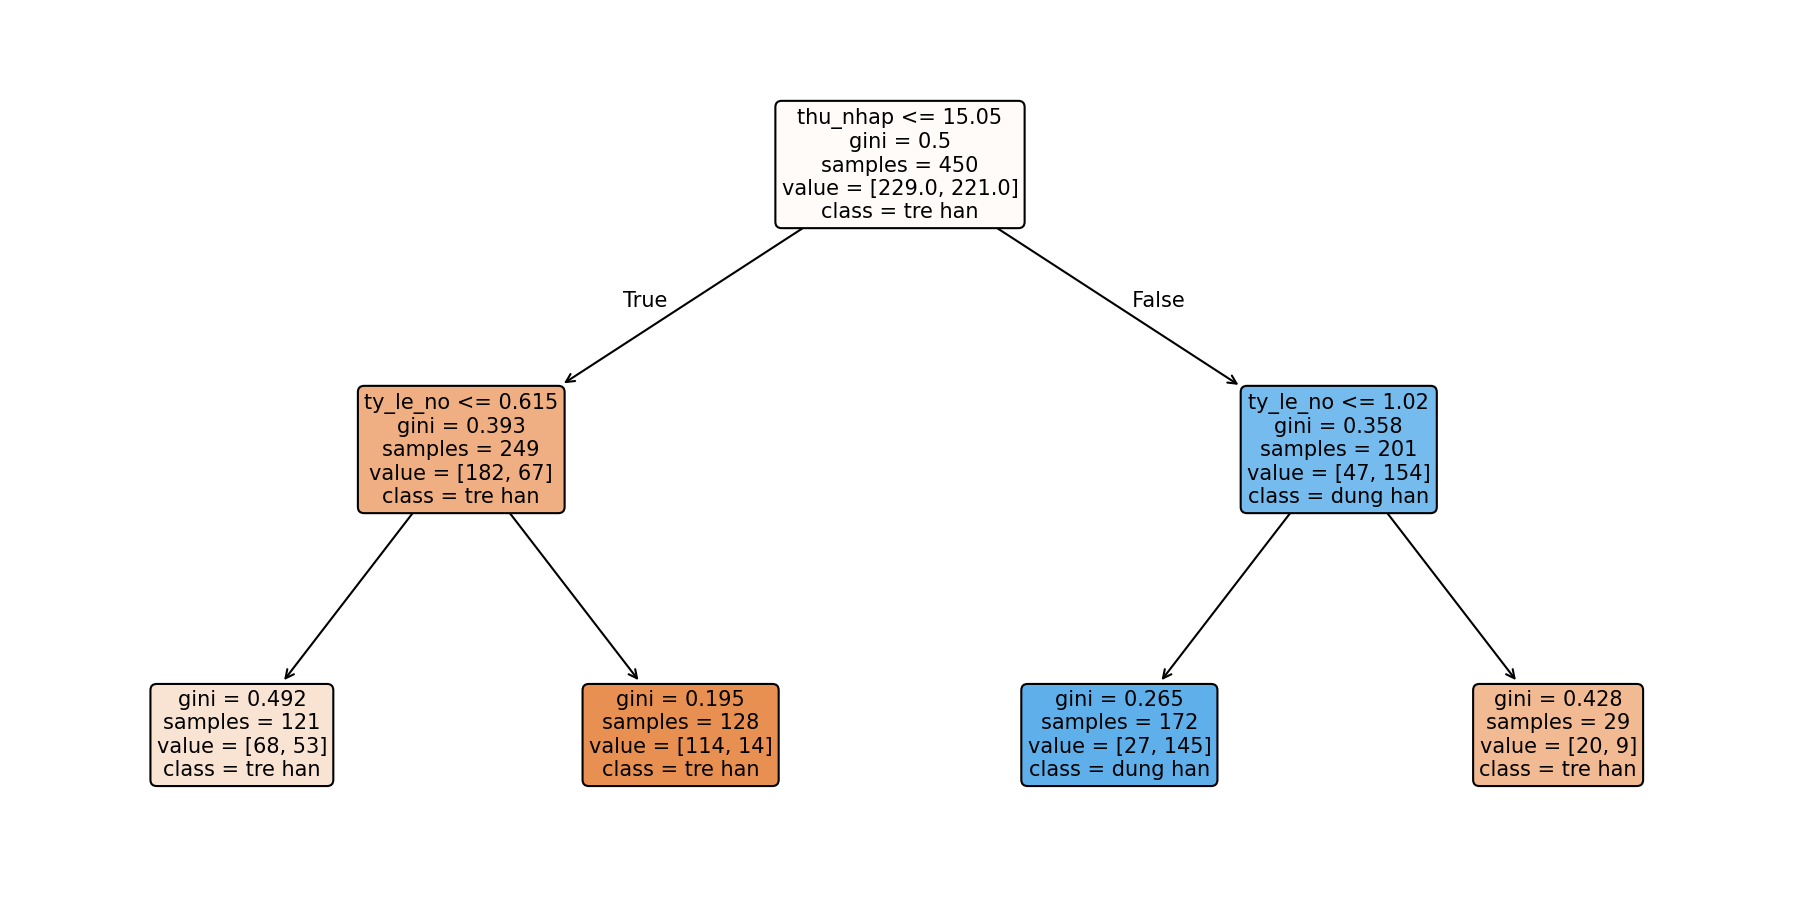

In [16]:
#Bài tập 2: Tự tìm câu hỏi gốc trên dữ liệu thật
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text


def gini(nhan):
    if len(nhan) == 0:
        return 0.0
    p1 = np.mean(nhan)
    return 1.0 - p1 ** 2 - (1.0 - p1) ** 2


def tim_cau_hoi(X, y):
    y_arr = np.asarray(y)
    n = len(y_arr)
    g_goc = gini(y_arr)

    cot_tot = None
    nguong_tot = None
    g_sau_tot = g_goc
    giam_max = -1.0

    for cot in X.columns:
        gia_tri = X[cot].to_numpy()
        cac_muc = np.sort(np.unique(gia_tri))

        for a, b in zip(cac_muc[:-1], cac_muc[1:]):
            nguong = (a + b) / 2.0
            di_trai = gia_tri <= nguong
            trai = y_arr[di_trai]
            phai = y_arr[~di_trai]

            g_chia = (len(trai) / n) * gini(trai) + (len(phai) / n) * gini(phai)
            giam = g_goc - g_chia

            if giam > giam_max:
                giam_max = giam
                g_sau_tot = g_chia
                cot_tot = cot
                nguong_tot = nguong

    return cot_tot, nguong_tot, g_goc, g_sau_tot, giam_max


df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cot, nguong, g_goc, g_sau, giam = tim_cau_hoi(X_tr, y_tr)
print("Ket qua ham tim_cau_hoi tren 450 khach tap hoc:")
print(f" Cot tot nhat   : {cot}")
print(f" Nguong tot nhat: {nguong:.2f}")
print(f" Gini nut goc   : {g_goc:.4f}")
print(f" Gini sau chia  : {g_sau:.4f}")
print(f" Gini giam      : {giam:.4f}")
print()

cay = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr)
print("Doi chieu voi scikit-learn:")
print(export_text(cay, feature_names=list(X.columns), decimals=2))

print("Cau hoi: Cay quyet dinh chon cau hoi goc nhu the nao?")
print("Tra loi: Ham duyet qua moi cot va thu tat ca trung diem giua hai gia tri lien tiep lam nguong chia. Tai moi nguong, tinh Gini trung binh co trong so cua hai nhanh trai va phai. Cap (thu_nhap, 15.05) cho muc giam Gini lon nhat nen duoc chon lam cau hoi goc, trung khop voi scikit-learn.")

Ket qua ham tim_cau_hoi tren 450 khach tap hoc:
 Cot tot nhat   : thu_nhap
 Nguong tot nhat: 15.05
 Gini nut goc   : 0.4998
 Gini sau chia  : 0.3777
 Gini giam      : 0.1221

Doi chieu voi scikit-learn:
|--- thu_nhap <= 15.05
|   |--- class: 0
|--- thu_nhap >  15.05
|   |--- class: 1

Cau hoi: Cay quyet dinh chon cau hoi goc nhu the nao?
Tra loi: Ham duyet qua moi cot va thu tat ca trung diem giua hai gia tri lien tiep lam nguong chia. Tai moi nguong, tinh Gini trung binh co trong so cua hai nhanh trai va phai. Cap (thu_nhap, 15.05) cho muc giam Gini lon nhat nen duoc chon lam cau hoi goc, trung khop voi scikit-learn.


In [17]:
#Bài tập 3: Gini hay entropy
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Do sau  tap hoc (entropy)  kiem dinh cheo (entropy)")
diem_ent = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)
    diem_ent[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    acc_hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {d:2d}     {acc_hoc:.4f}             {diem_ent[d]:.4f}")

d_tot = max(diem_ent, key=diem_ent.get)
cay_ent = DecisionTreeClassifier(criterion="entropy", max_depth=d_tot, random_state=0)
cay_ent.fit(X_tr, y_tr)
acc_te_ent = accuracy_score(y_te, cay_ent.predict(X_te))

cay_gini = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=0)
cay_gini.fit(X_tr, y_tr)
acc_te_gini = accuracy_score(y_te, cay_gini.predict(X_te))

print()
print(f"Entropy: do sau tot nhat = {d_tot}, CV = {diem_ent[d_tot]:.4f}, accuracy kiem tra = {acc_te_ent:.4f}")
print(f"Gini   : do sau tot nhat = 5, CV = 0.8333, accuracy kiem tra = {acc_te_gini:.4f}")
print()
print("Cau hoi: Doi thuoc do sang entropy co lam ket qua khac di nhieu khong?")
print("Tra loi: Khong, ket qua gan nhu khong thay doi nhieu vi ca hai thuoc do deu danh gia muc do lan lon cua nut tuong duong nhau.")

Do sau  tap hoc (entropy)  kiem dinh cheo (entropy)
  1     0.7467             0.7244
  2     0.7711             0.7133
  3     0.7733             0.7489
  4     0.8511             0.8111
  5     0.8956             0.8222
  6     0.9111             0.8222
  7     0.9378             0.8089
  8     0.9533             0.7933
  9     0.9778             0.7844
 10     0.9867             0.7978
 11     0.9933             0.7911
 12     0.9978             0.7822
 13     1.0000             0.7822
 14     1.0000             0.7822
 15     1.0000             0.7867

Entropy: do sau tot nhat = 5, CV = 0.8222, accuracy kiem tra = 0.8467
Gini   : do sau tot nhat = 5, CV = 0.8333, accuracy kiem tra = 0.8533

Cau hoi: Doi thuoc do sang entropy co lam ket qua khac di nhieu khong?
Tra loi: Khong, ket qua gan nhu khong thay doi nhieu vi ca hai thuoc do deu danh gia muc do lan lon cua nut tuong duong nhau.


In [18]:
#Bài tập 4: Cắt tỉa bằng số khách tối thiểu ở lá
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("min_samples_leaf  tap hoc  kiem dinh cheo")
diem_la = {}
for m in [1, 2, 5, 10, 20, 40]:
    mh = DecisionTreeClassifier(min_samples_leaf=m, random_state=0)
    diem_la[m] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    acc_hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {m:16d}  {acc_hoc:.4f}   {diem_la[m]:.4f}")

m_tot = max(diem_la, key=diem_la.get)
cay_la = DecisionTreeClassifier(min_samples_leaf=m_tot, random_state=0)
cay_la.fit(X_tr, y_tr)
acc_te_la = accuracy_score(y_te, cay_la.predict(X_te))

print()
print(f"min_samples_leaf tot nhat = {m_tot} (CV = {diem_la[m_tot]:.4f})")
print(f"Accuracy tap kiem tra (min_samples_leaf = {m_tot}): {acc_te_la:.4f}")
print("Accuracy tap kiem tra (cay max_depth = 5)      : 0.8533")
print()
print("Cau hoi: So voi cay sau 5, cach cat tia nao cho ket qua tot hon tren bo du lieu nay?")
if acc_te_la > 0.8533:
    print("Tra loi: Cat tia bang min_samples_leaf cho ket qua tot hon cay sau 5 tren bo du lieu nay.")
elif acc_te_la < 0.8533:
    print("Tra loi: Gioi han do sau max_depth = 5 cho ket qua tot hon cat tia bang min_samples_leaf tren bo du lieu nay.")
else:
    print("Tra loi: Hai cach cat tia cho ket qua tuong duong nhau tren bo du lieu nay.")

min_samples_leaf  tap hoc  kiem dinh cheo
                1  1.0000   0.7733
                2  0.9467   0.7822
                5  0.8956   0.8067
               10  0.8600   0.8089
               20  0.8422   0.8089
               40  0.7822   0.7133

min_samples_leaf tot nhat = 10 (CV = 0.8089)
Accuracy tap kiem tra (min_samples_leaf = 10): 0.8467
Accuracy tap kiem tra (cay max_depth = 5)      : 0.8533

Cau hoi: So voi cay sau 5, cach cat tia nao cho ket qua tot hon tren bo du lieu nay?
Tra loi: Gioi han do sau max_depth = 5 cho ket qua tot hon cat tia bang min_samples_leaf tren bo du lieu nay.


In [19]:
#Bài tập 5: Độ quan trọng bằng cách xáo trộn
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_te_nn = X_te.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te))

rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)

qt_gini = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong theo feature_importances_ (Gini):")
print(qt_gini.sort_values(ascending=False).round(4).to_string())
print()

kq_perm = permutation_importance(
    rung_nn, X_te_nn, y_te, n_repeats=20, random_state=0
)
qt_perm = pd.Series(kq_perm.importances_mean, index=X_te_nn.columns)
print("Do quan trong trung binh theo permutation_importance:")
print(qt_perm.sort_values(ascending=False).round(4).to_string())
print()

thu_hang_perm = list(qt_perm.sort_values(ascending=False).index).index("so_ngau_nhien") + 1
thu_hang_gini = list(qt_gini.sort_values(ascending=False).index).index("so_ngau_nhien") + 1

print("Cau hoi 1: Cot ngau nhien xep thu may theo permutation_importance va so voi feature_importances_?")
print(f"Tra loi  : Theo permutation_importance, cot so_ngau_nhien xep thu {thu_hang_perm} (xap xi 0), giam manh so voi vi tri thu {thu_hang_gini} theo feature_importances_.")
print()
print("Cau hoi 2: Giai thich su khac nhau giua hai cach do?")
print("Tra loi  : feature_importances_ cong don muc giam Gini tren tap hoc nen uu ai cot lien tuc co 450 gia tri khac nhau de chia tach mau le, trong khi cot nhi phan chi co 1 nguong chia. Con permutation_importance xao tron cot tren tap kiem tra va do muc giam accuracy; vi cot ngau nhien vo dung nen xao tron no khong lam mo hinh kem di.")

Do quan trong theo feature_importances_ (Gini):
thu_nhap              0.4269
ty_le_no              0.2696
so_ngau_nhien         0.1499
co_viec_on_dinh       0.0773
so_nguoi_phu_thuoc    0.0764

Do quan trong trung binh theo permutation_importance:
thu_nhap              0.3073
ty_le_no              0.1993
co_viec_on_dinh       0.1117
so_nguoi_phu_thuoc    0.0497
so_ngau_nhien         0.0017

Cau hoi 1: Cot ngau nhien xep thu may theo permutation_importance va so voi feature_importances_?
Tra loi  : Theo permutation_importance, cot so_ngau_nhien xep thu 5 (xap xi 0), giam manh so voi vi tri thu 3 theo feature_importances_.

Cau hoi 2: Giai thich su khac nhau giua hai cach do?
Tra loi  : feature_importances_ cong don muc giam Gini tren tap hoc nen uu ai cot lien tuc co 450 gia tri khac nhau de chia tach mau le, trong khi cot nhi phan chi co 1 nguong chia. Con permutation_importance xao tron cot tren tap kiem tra va do muc giam accuracy; vi cot ngau nhien vo dung nen xao tron no khong lam 

In [20]:
#Bài tập 6: Rừng cho bài toán hồi quy
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cay = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)
rung = RandomForestRegressor(n_estimators=200, random_state=0).fit(X_tr, y_tr)

mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
mae_rung = mean_absolute_error(y_te, rung.predict(X_te))

print("MAE tren tap kiem tra (ty dong):")
print(f" Cay sau 3    : {mae_cay:.4f}")
print(f" Rung 200 cay : {mae_rung:.4f}")
print(f" Duong thang  : {mae_duong:.4f}")
print()

can_250 = pd.DataFrame({"dien_tich": [250.0]})
print("Du doan gia can 250 m2 (ty dong):")
print(f" Cay sau 3    : {cay.predict(can_250)[0]:.2f}")
print(f" Rung 200 cay : {rung.predict(can_250)[0]:.2f}")
print(f" Duong thang  : {duong.predict(can_250)[0]:.2f}")
print()

print("Cau hoi 1: So MAE cua rung voi cay sau 3 va duong thang?")
print("Tra loi  : Rung 200 cay co MAE thap hon cay sau 3 nhung van cao hon duong thang hoi quy tuyen tinh vi du lieu gia nha co quan he tuyen tinh.")
print()
print("Cau hoi 2: Rung co ngoai suy duoc khong? Giai thich?")
print("Tra loi  : Khong. Khi gap can 250 m2 vuot ngoai khoang dien tich tap hoc, moi cay trong rung deu dua mau nay vao nut la ngoai cung ben phai va tra ve gia trung binh cua cac can rong nhat da thay. Trung binh cua 200 cay van bi chan tran, khong the tang tuyen tinh nhu duong thang.")

MAE tren tap kiem tra (ty dong):
 Cay sau 3    : 0.5039
 Rung 200 cay : 0.4559
 Duong thang  : 0.2578

Du doan gia can 250 m2 (ty dong):
 Cay sau 3    : 9.40
 Rung 200 cay : 9.20
 Duong thang  : 19.91

Cau hoi 1: So MAE cua rung voi cay sau 3 va duong thang?
Tra loi  : Rung 200 cay co MAE thap hon cay sau 3 nhung van cao hon duong thang hoi quy tuyen tinh vi du lieu gia nha co quan he tuyen tinh.

Cau hoi 2: Rung co ngoai suy duoc khong? Giai thich?
Tra loi  : Khong. Khi gap can 250 m2 vuot ngoai khoang dien tich tap hoc, moi cay trong rung deu dua mau nay vao nut la ngoai cung ben phai va tra ve gia trung binh cua cac can rong nhat da thay. Trung binh cua 200 cay van bi chan tran, khong the tang tuyen tinh nhu duong thang.
